In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import  torchvision 
import  torchvision.transforms as transforms
from torch.utils.data import DataLoader 
import matplotlib.pyplot as plt
import random
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [2]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [3]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [4]:
image, label = train_dataset[0]

print("Image shape: ", image.shape)
print("Label: ", label)
print("Image tensor: ", image)

Image shape:  torch.Size([1, 28, 28])
Label:  5
Image tensor:  tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.

In [5]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
First 10 labels: tensor([5, 7, 1, 9, 5, 3, 3, 0, 2, 9])


In [6]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(kernel_size=2)

        self.conv2 = nn.Conv2d(
        in_channels=16,
        out_channels=32,
        kernel_size=3
        )

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            in_features=800,
            out_features=128
        )

        self.fc2 = nn.Linear(
            in_features=128,
            out_features=10
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

In [7]:
model = CNN()

print(model)

CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=800, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [9]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [10]:
num_epochs = 5

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

Epoch [1/5], Loss: 0.2179
Epoch [2/5], Loss: 0.0646
Epoch [3/5], Loss: 0.0439
Epoch [4/5], Loss: 0.0345
Epoch [5/5], Loss: 0.0279


In [11]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 98.67%


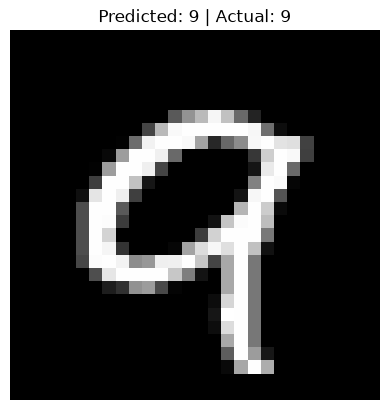

Prediction probabilities:
Digit 0: 0.00%
Digit 1: 0.00%
Digit 2: 0.00%
Digit 3: 0.00%
Digit 4: 0.00%
Digit 5: 0.00%
Digit 6: 0.00%
Digit 7: 0.00%
Digit 8: 0.00%
Digit 9: 99.99%


In [12]:
index = random.randint(0, len(test_dataset) - 1)
image, label = test_dataset[index]

model.eval()

with torch.no_grad():
    output = model(image.unsqueeze(0))
    prediction = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Predicted: {prediction} | Actual: {label}")
plt.axis("off")
plt.show()

probabilities = torch.softmax(output, dim=1)

print("Prediction probabilities:")

for digit, probability in enumerate(probabilities[0]):
    print(f"Digit {digit}: {probability.item() * 100:.2f}%")

In [13]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

print(classification_report(all_labels, all_predictions))

[[ 974    0    1    0    0    0    4    1    0    0]
 [   0 1130    0    4    0    0    1    0    0    0]
 [   0    0 1025    4    0    0    0    3    0    0]
 [   0    0    0 1010    0    0    0    0    0    0]
 [   0    0    0    0  979    0    2    0    0    1]
 [   1    0    1   26    0  862    1    1    0    0]
 [   1    2    0    0    1    3  949    0    2    0]
 [   1    3    9    1    0    0    0 1012    1    1]
 [   3    1    1   14    0    1    3    2  942    7]
 [   1    2    0    7    6    5    0    4    0  984]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.95      1.00      0.97      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.97      0.98       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98   

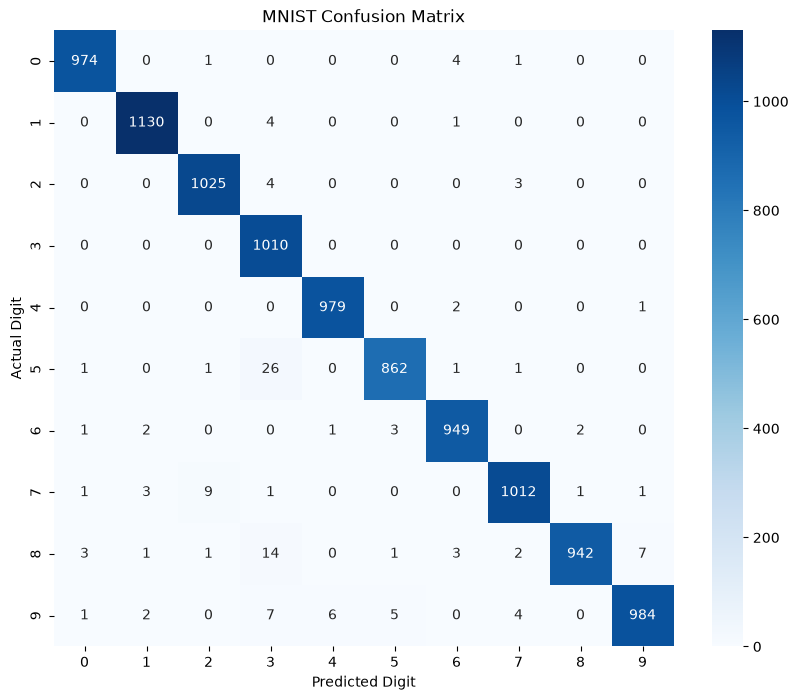

In [14]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST Confusion Matrix")

plt.show()

In [16]:
torch.save(model.state_dict(), "mnist_cnn.pth")

print("Model saved successfully!")

Model saved successfully!
